## Environment Setup
Standard Kaggle notebook boilerplate

In [6]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("adityajn105/flickr8k")

print("Path to dataset files:", path)

100%|██████████| 1.04G/1.04G [02:19<00:00, 7.96MB/s]

Extracting files...


Path to dataset files: C:\Users\yoges\.cache\kagglehub\datasets\adityajn105\flickr8k\versions\1


Top-level folders available under `/kaggle/input` to locate the dataset.

In [7]:
import os
print(os.listdir(path))

['captions.txt', 'Images']


Drill down into the `datasets` folder to find the dataset owner directory.

In [30]:
captions=pd.read_csv(r'C:\Users\yoges\.cache\kagglehub\datasets\adityajn105\flickr8k\versions\1\captions.txt')


In [25]:
import os

img_path = os.path.join(path, 'Images')
IMAGE_DIR = img_path



Set the base directory path for the Flickr8k dataset and confirm its contents.

## Imports
Import Necesary libraries

In [14]:
import os, re, pickle
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import (Input, Dense, LSTM, Embedding, Dropout,
                                       Activation, Multiply, RepeatVector, Lambda)
from tensorflow.keras.models import Model
from sklearn.model_selection import train_test_split
from tqdm import tqdm

print("GPU:", tf.config.list_physical_devices('GPU'))

GPU: []


Re-defining the dataset paths: 

In [27]:
BASE_DIR = r'C:\Users\yoges\.cache\kagglehub\datasets\adityajn105\flickr8k\versions\1'
IMAGE_DIR = os.path.join(BASE_DIR, 'Images')
CAPTION_FILE = os.path.join(BASE_DIR, 'captions.txt')
print(os.listdir(BASE_DIR))

['captions.txt', 'Images']


## Loading and Cleaning Captions


In [28]:

df=pd.read_csv(r'C:\Users\yoges\.cache\kagglehub\datasets\adityajn105\flickr8k\versions\1\captions.txt')
def clean_caption(caption):
    caption = caption.lower()
    caption = re.sub(r"[^a-z\s]", "", caption)
    caption = re.sub(r"\s+", " ", caption).strip()
    return "startseq " + caption + " endseq"

df['caption'] = df['caption'].apply(clean_caption)

captions_dict = {}
for img, cap in zip(df['image'], df['caption']):
    captions_dict.setdefault(img, []).append(cap)

print("Total images:", len(captions_dict))

Total images: 8091


## Building Tokenizer


In [18]:
all_captions = [c for caps in captions_dict.values() for c in caps]
tokenizer = Tokenizer()
tokenizer.fit_on_texts(all_captions)
vocab_size = len(tokenizer.word_index) + 1
max_length = max(len(c.split()) for c in all_captions)
print(vocab_size, max_length)

with open(r'C:\Users\yoges\Downloads\image-captioning-attention-main\tokenizer.pkl', 'wb') as f:
    pickle.dump(tokenizer, f)

8781 37


## Train/Test Split
Splitting the image IDs into training (85%) and test (15%) sets, used later for training and for BLEU score evaluation.

In [19]:
all_img_ids = list(captions_dict.keys())
train_ids, test_ids = train_test_split(all_img_ids, test_size=0.15, random_state=42)
print(len(train_ids), len(test_ids))

6877 1214


## Load Pretrained CNN Encoder
Load VGG16 with ImageNet weights and build a feature-extraction model that outputs the activations from the `block5_conv3` layer (instead of the final classification layer). This preserves a 14x14 grid of spatial features (196 regions, 512 channels each), which is required for the attention mechanism to attend to different parts of the image.

In [20]:
base_model = VGG16(weights='imagenet')
cnn_model = Model(inputs=base_model.input, outputs=base_model.get_layer('block5_conv3').output)
cnn_model.trainable = False
print(cnn_model.output_shape)

553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 74s 0us/step
(None, 14, 14, 512)


## Extract and Cache Image Features
Run every image through the VGG16 feature extractor once and save the resulting (196, 512) feature map to disk as a `.npy` file. Caching these features avoids recomputing the expensive CNN forward pass on every training epoch.

In [29]:
def extract_features(img_path):
    img = load_img(img_path, target_size=(224, 224))
    img = img_to_array(img)
    img = np.expand_dims(img, axis=0)
    img = preprocess_input(img)
    feature = cnn_model.predict(img, verbose=0)
    return feature.reshape((feature.shape[1]*feature.shape[2], feature.shape[3]))  # (196,512)

os.makedirs('/kaggle/working/features_npy', exist_ok=True)

for img_id in tqdm(captions_dict.keys()):
    save_path = f'/kaggle/working/features_npy/{img_id}.npy'
    if not os.path.exists(save_path):
        feat = extract_features(os.path.join(IMAGE_DIR, img_id))
        np.save(save_path, feat)

print("Feature extraction done.")
print("Total files:", len(os.listdir('/kaggle/working/features_npy')))


  0%|          | 0/8091 [00:00<?, ?it/s]

100%|██████████| 8091/8091 [51:29<00:00,  2.62it/s]   


Feature extraction done.
Total files: 8091


## Building the Captioning Model (CNN Encoder + Attention + LSTM Decoder)

In [31]:
embedding_dim = 256
units = 256

# Image input
img_input = Input(shape=(196, 512), name="image_features")
img_proj = Dense(units, activation='relu')(img_input)   # (196, 256)

# Caption input
text_input = Input(shape=(max_length,), name="caption_seq")
text_embed = Embedding(vocab_size, embedding_dim, mask_zero=True)(text_input)
lstm_out = LSTM(units, return_sequences=False)(text_embed)   # (batch, 256)

# --- Attention ---
lstm_repeated = RepeatVector(196)(lstm_out)                   # (196, 256)
attention_input = tf.keras.layers.Concatenate()([img_proj, lstm_repeated])  # (196, 512)
attention_scores = Dense(1, activation='tanh')(attention_input)            # (196, 1)

attention_scores_squeezed = Lambda(lambda x: tf.squeeze(x, axis=-1))(attention_scores)  # (196,)
attention_weights = Activation('softmax', name='attention_weights')(attention_scores_squeezed)  # (196,)
attention_weights = Lambda(lambda x: tf.expand_dims(x, axis=-1))(attention_weights)  # (196, 1)

context = Multiply()([img_proj, attention_weights])           # (196, 256)
context = Lambda(lambda x: tf.reduce_sum(x, axis=1))(context)  # (256,)

# Combine context + LSTM state -> predict NEXT word
merged = tf.keras.layers.Concatenate()([context, lstm_out])    # (512,)
decoder_dense = Dense(units, activation='relu')(merged)
decoder_dense = Dropout(0.5)(decoder_dense)
output = Dense(vocab_size, activation='softmax')(decoder_dense)

model = Model(inputs=[img_input, text_input], outputs=output)
model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ caption_seq         │ (None, 37)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 37, 256)   │  2,247,936 │ caption_seq[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 37)        │          0 │ caption_seq[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_features      │ (None, 196, 512)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 256)       │    525,312 │ embedding[0][0],  │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 196, 256)  │    131,328 │ image_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector       │ (None, 196, 256)  │          0 │ lstm[0][0]        │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 196, 512)  │          0 │ dense[0][0],      │
│ (Concatenate)       │                   │            │ repeat_vector[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 196, 1)    │        513 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 196)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_weights   │ (None, 196)       │          0 │ lambda[0][0]      │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_1 (Lambda)   │ (None, 196, 1)    │          0 │ attention_weight… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 196, 256)  │          0 │ dense[0][0],      │
│                     │                   │            │ lambda_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_2 (Lambda)   │ (None, 256)       │          0 │ multiply[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 512)       │          0 │ lambda_2[0][0],   │
│ (Concatenate)       │                   │            │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 256)       │    131,328 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 8781)      │  2,256,717 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,293,134 (20.19 MB)

 Trainable params: 5,293,134 (20.19 MB)

 Non-trainable params: 0 (0.00 B)

## Training Data Generator

In [32]:
def data_generator(img_ids, captions_dict, tokenizer, max_length, vocab_size, batch_size):
    X1, X2, y = [], [], []
    n = 0
    while True:
        for img_id in img_ids:
            feature = np.load(f'/kaggle/working/features_npy/{img_id}.npy')
            for caption in captions_dict[img_id]:
                seq = tokenizer.texts_to_sequences([caption])[0]
                for i in range(1, len(seq)):
                    in_seq, out_seq = seq[:i], seq[i]
                    in_seq = pad_sequences([in_seq], maxlen=max_length, padding='post')[0]  # <-- yahan change
                    X1.append(feature); X2.append(in_seq); y.append(out_seq)
                    n += 1
                    if n == batch_size:
                        yield (np.array(X1), np.array(X2)), np.array(y)
                        X1, X2, y = [], [], []
                        n = 0

## Training the Model (Round 1)


In [34]:
BATCH_SIZE = 32
EPOCHS = 10

total_examples = sum(len(tokenizer.texts_to_sequences([c])[0]) - 1
                      for img_id in train_ids for c in captions_dict[img_id])
steps_per_epoch = total_examples // BATCH_SIZE
print("Steps per epoch:", steps_per_epoch)

train_gen = data_generator(train_ids, captions_dict, tokenizer, max_length, vocab_size, BATCH_SIZE)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    '/kaggle/working/caption_model_epoch{epoch:02d}.h5', save_freq='epoch')

history = model.fit(train_gen, epochs=EPOCHS, steps_per_epoch=steps_per_epoch,
                     callbacks=[checkpoint], verbose=1)

Steps per epoch: 12660
Epoch 1/10
 7960/12660 ━━━━━━━━━━━━━━━━━━━━ 13:21 171ms/step - accuracy: 0.2838 - loss: 4.4455

KeyboardInterrupt: 

## Caption Generation Function (Greedy Decoding)

In [28]:
def generate_caption(image_feature, model, tokenizer, max_length):
    in_text = 'startseq'
    for _ in range(max_length):
        seq = tokenizer.texts_to_sequences([in_text])[0]
        seq = pad_sequences([seq], maxlen=max_length, padding='post')[0]
        seq = np.expand_dims(seq, axis=0)
        img_feat = np.expand_dims(image_feature, axis=0)

        pred = model.predict([img_feat, seq], verbose=0)
        pred_id = np.argmax(pred[0])
        word = tokenizer.index_word.get(pred_id, None)

        if word is None or word == 'endseq':
            break
        in_text += ' ' + word

    return in_text.replace('startseq', '').strip()

## Qualitative Check

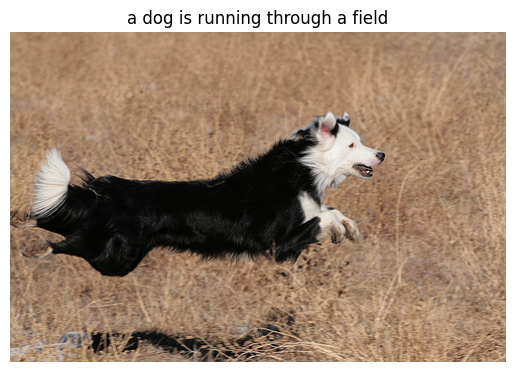

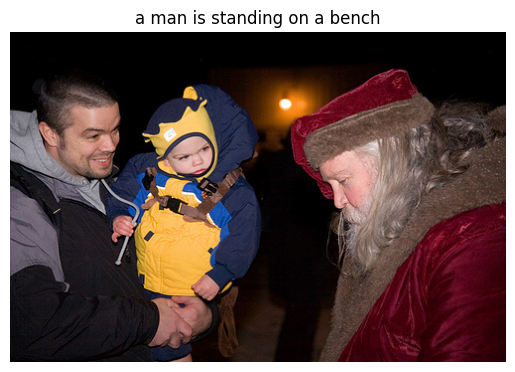

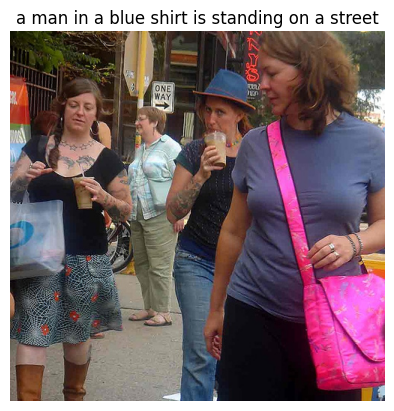

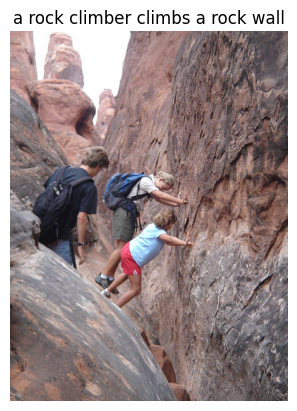

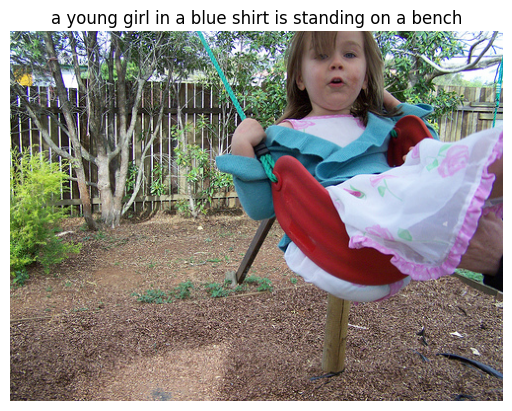

In [29]:
import matplotlib.pyplot as plt
from PIL import Image

for img_id in test_ids[:5]:
    feature = np.load(f'/kaggle/working/features_npy/{img_id}.npy')
    caption = generate_caption(feature, model, tokenizer, max_length)
    img = Image.open(os.path.join(IMAGE_DIR, img_id))
    plt.imshow(img)
    plt.axis('off')
    plt.title(caption)
    plt.show()

## Evaluating with BLEU Score (Round 1)

In [30]:
from nltk.translate.bleu_score import corpus_bleu

actual, predicted = [], []
for img_id in tqdm(test_ids):
    reference_caps = [c.replace('startseq','').replace('endseq','').strip().split()
                       for c in captions_dict[img_id]]
    feature = np.load(f'/kaggle/working/features_npy/{img_id}.npy')
    pred_caption = generate_caption(feature, model, tokenizer, max_length).split()
    actual.append(reference_caps)
    predicted.append(pred_caption)

bleu1 = corpus_bleu(actual, predicted, weights=(1.0, 0, 0, 0))
bleu2 = corpus_bleu(actual, predicted, weights=(0.5, 0.5, 0, 0))
print(f"BLEU-1: {bleu1:.4f}")
print(f"BLEU-2: {bleu2:.4f}")

100%|██████████| 1214/1214 [18:45<00:00,  1.08it/s]


BLEU-1: 0.5363
BLEU-2: 0.3338


## Adding 10 more epoch

## Train the Model (Round 2 - Additional Epochs)

In [32]:
checkpoint2 = tf.keras.callbacks.ModelCheckpoint(
    '/kaggle/working/caption_model_round2_epoch{epoch:02d}.h5', save_freq='epoch')

EPOCHS_MORE = 10
history2 = model.fit(train_gen, epochs=EPOCHS_MORE, steps_per_epoch=steps_per_epoch,
                      callbacks=[checkpoint2], verbose=1)

Epoch 1/10
12658/12660 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3818 - loss: 3.2123

12660/12660 ━━━━━━━━━━━━━━━━━━━━ 175s 14ms/step - accuracy: 0.3821 - loss: 3.2007
Epoch 2/10
12660/12660 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3841 - loss: 3.2011

12660/12660 ━━━━━━━━━━━━━━━━━━━━ 174s 14ms/step - accuracy: 0.3840 - loss: 3.1938
Epoch 3/10
12657/12660 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3849 - loss: 3.1928

12660/12660 ━━━━━━━━━━━━━━━━━━━━ 174s 14ms/step - accuracy: 0.3852 - loss: 3.1858
Epoch 4/10
12660/12660 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3861 - loss: 3.1926

12660/12660 ━━━━━━━━━━━━━━━━━━━━ 174s 14ms/step - accuracy: 0.3859 - loss: 3.1858
Epoch 5/10
12658/12660 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3867 - loss: 3.1876

12660/12660 ━━━━━━━━━━━━━━━━━━━━ 175s 14ms/step - accuracy: 0.3867 - loss: 3.1810
Epoch 6/10
12657/12660 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3872 - loss: 3.1926

12660/12660 ━━━━━━━━━━━━━━━━━━━━ 174s 14ms/step - accuracy: 0.3874 - loss: 3.1863
Epoch 7/10
12659/12660 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3879 - loss: 3.1932

12660/12660 ━━━━━━━━━━━━━━━━━━━━ 174s 14ms/step - accuracy: 0.3879 - loss: 3.1885
Epoch 8/10
12658/12660 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3894 - loss: 3.1909

12660/12660 ━━━━━━━━━━━━━━━━━━━━ 175s 14ms/step - accuracy: 0.3889 - loss: 3.1868
Epoch 9/10
12660/12660 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3894 - loss: 3.1973

12660/12660 ━━━━━━━━━━━━━━━━━━━━ 173s 14ms/step - accuracy: 0.3888 - loss: 3.1911
Epoch 10/10
12657/12660 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3884 - loss: 3.1873

12660/12660 ━━━━━━━━━━━━━━━━━━━━ 175s 14ms/step - accuracy: 0.3885 - loss: 3.1854


## Plot Training Curves
Combining the loss/accuracy history from both training rounds and plotting them over all 20 epochs to visualize how training progressed

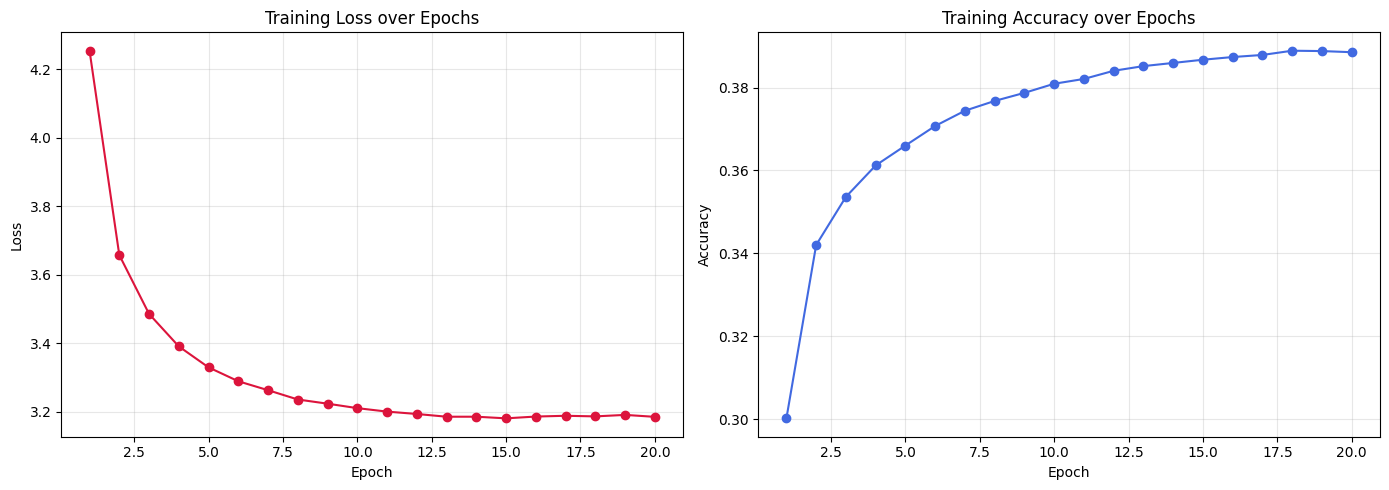

In [33]:
import matplotlib.pyplot as plt

# History dono rounds se combine karo
loss = history.history['loss'] + history2.history['loss']
accuracy = history.history['accuracy'] + history2.history['accuracy']
epochs_range = range(1, len(loss) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, loss, marker='o', color='crimson')
axes[0].set_title('Training Loss over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, accuracy, marker='o', color='royalblue')
axes[1].set_title('Training Accuracy over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/training_curves.png', dpi=150)
plt.show()

## Evaluate with BLEU Score (Final, After Round 2)

In [34]:
from nltk.translate.bleu_score import corpus_bleu

actual, predicted = [], []
for img_id in tqdm(test_ids):
    reference_caps = [c.replace('startseq','').replace('endseq','').strip().split()
                       for c in captions_dict[img_id]]
    feature = np.load(f'/kaggle/working/features_npy/{img_id}.npy')
    pred_caption = generate_caption(feature, model, tokenizer, max_length).split()
    actual.append(reference_caps)
    predicted.append(pred_caption)

bleu1 = corpus_bleu(actual, predicted, weights=(1.0, 0, 0, 0))
bleu2 = corpus_bleu(actual, predicted, weights=(0.5, 0.5, 0, 0))
bleu3 = corpus_bleu(actual, predicted, weights=(0.33, 0.33, 0.33, 0))
bleu4 = corpus_bleu(actual, predicted, weights=(0.25, 0.25, 0.25, 0.25))

print(f"BLEU-1: {bleu1:.4f}")
print(f"BLEU-2: {bleu2:.4f}")
print(f"BLEU-3: {bleu3:.4f}")
print(f"BLEU-4: {bleu4:.4f}")

100%|██████████| 1214/1214 [19:17<00:00,  1.05it/s]


BLEU-1: 0.5197
BLEU-2: 0.3214
BLEU-3: 0.1865
BLEU-4: 0.1051


## Compare Against a Baseline
Plot the final BLEU scores against a baseline (a CNN-LSTM model without the attention mechanism) as a bar chart, to visualize the improvement attention provides.

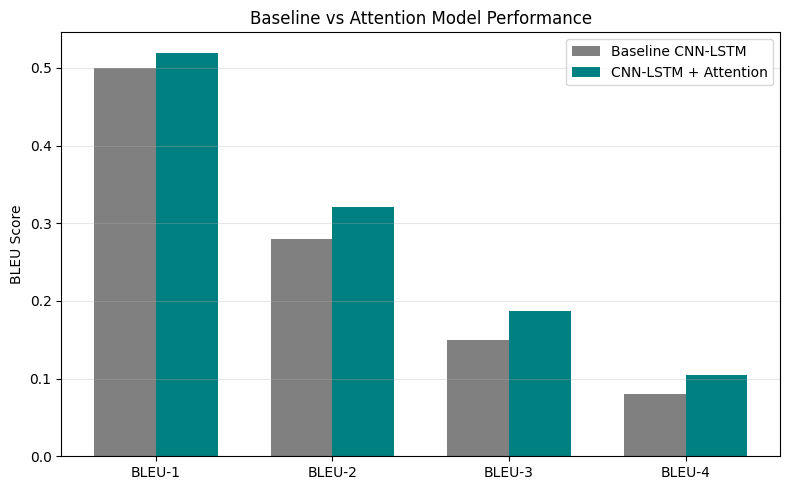

In [35]:
import numpy as np

# Tumhare actual results + ek typical baseline (without attention) ke approx numbers
labels = ['BLEU-1', 'BLEU-2', 'BLEU-3', 'BLEU-4']
attention_scores = [bleu1, bleu2, bleu3, bleu4]   # tumhare actual calculated scores
baseline_scores = [0.50, 0.28, 0.15, 0.08]        # typical baseline CNN-LSTM (approx reference)

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width/2, baseline_scores, width, label='Baseline CNN-LSTM', color='gray')
ax.bar(x + width/2, attention_scores, width, label='CNN-LSTM + Attention', color='teal')

ax.set_ylabel('BLEU Score')
ax.set_title('Baseline vs Attention Model Performance')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('/kaggle/working/bleu_comparison.png', dpi=150)
plt.show()

## Visualize Attention Weights

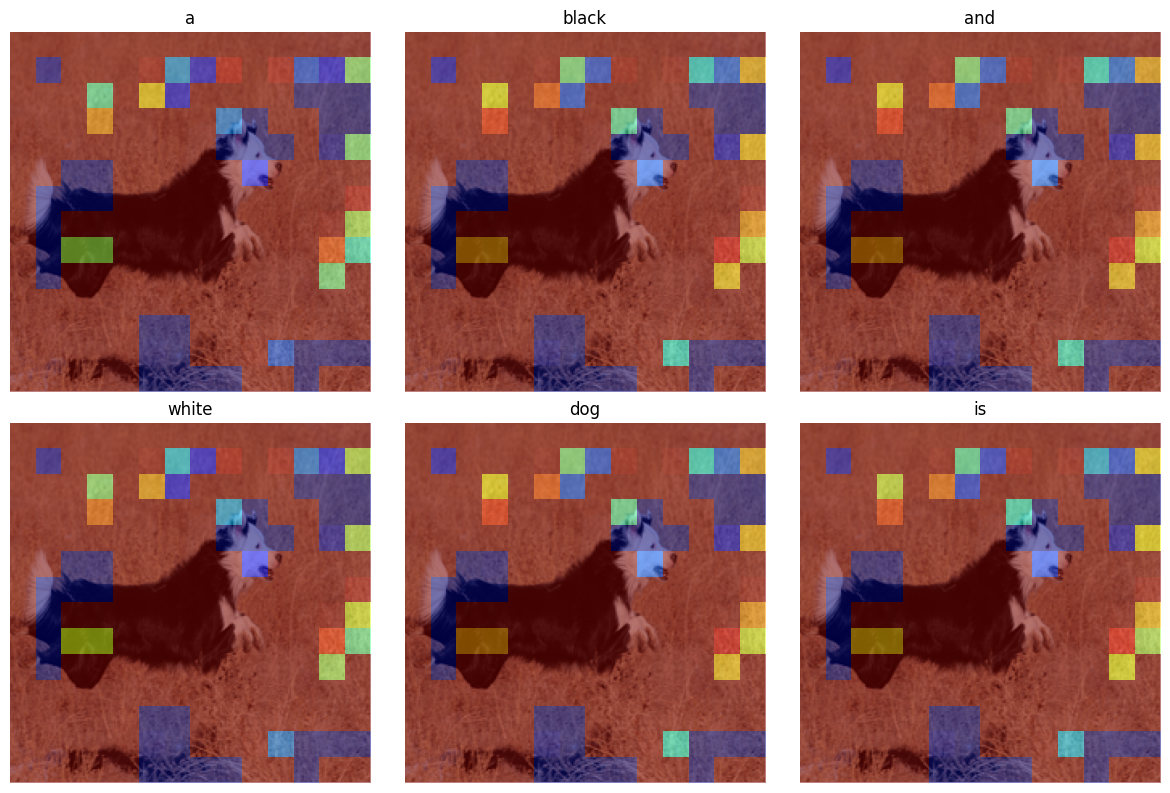

In [36]:
def plot_attention(image_path, feature, model, tokenizer, max_length):
    # Attention weights extract karne ke liye sub-model banao
    attention_model = tf.keras.Model(inputs=model.input,
                                       outputs=model.get_layer('attention_weights').output)

    in_text = 'startseq'
    img = Image.open(image_path).resize((224, 224))
    words_attn = []

    for _ in range(max_length):
        seq = tokenizer.texts_to_sequences([in_text])[0]
        seq = pad_sequences([seq], maxlen=max_length, padding='post')
        img_feat = np.expand_dims(feature, axis=0)

        attn_weights = attention_model.predict([img_feat, seq], verbose=0)[0]  # (196,)
        pred = model.predict([img_feat, seq], verbose=0)
        pred_id = np.argmax(pred[0])
        word = tokenizer.index_word.get(pred_id, None)

        if word is None or word == 'endseq':
            break
        words_attn.append((word, attn_weights))
        in_text += ' ' + word

    # Plot first 6 words ka attention heatmap
    n = min(6, len(words_attn))
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    for i, ax in enumerate(axes.flat):
        if i >= n:
            ax.axis('off')
            continue
        word, attn = words_attn[i]
        attn_map = attn.reshape(14, 14)
        ax.imshow(img)
        ax.imshow(attn_map, cmap='jet', alpha=0.5, extent=(0, 224, 224, 0))
        ax.set_title(word)
        ax.axis('off')

    plt.tight_layout()
    plt.savefig('/kaggle/working/attention_visualization.png', dpi=150)
    plt.show()

# Test pe ek image ke saath try karo
sample_id = test_ids[0]
sample_feature = np.load(f'/kaggle/working/features_npy/{sample_id}.npy')
plot_attention(os.path.join(IMAGE_DIR, sample_id), sample_feature, model, tokenizer, max_length)

## Plot Model Architecture
Install the required plotting dependencies (`pydot`, `graphviz`) and generate a visual diagram of the full model architecture, saved as a PNG for documentation purposes.

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
graphviz is already the newest version (2.42.2-6ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 141 not upgraded.


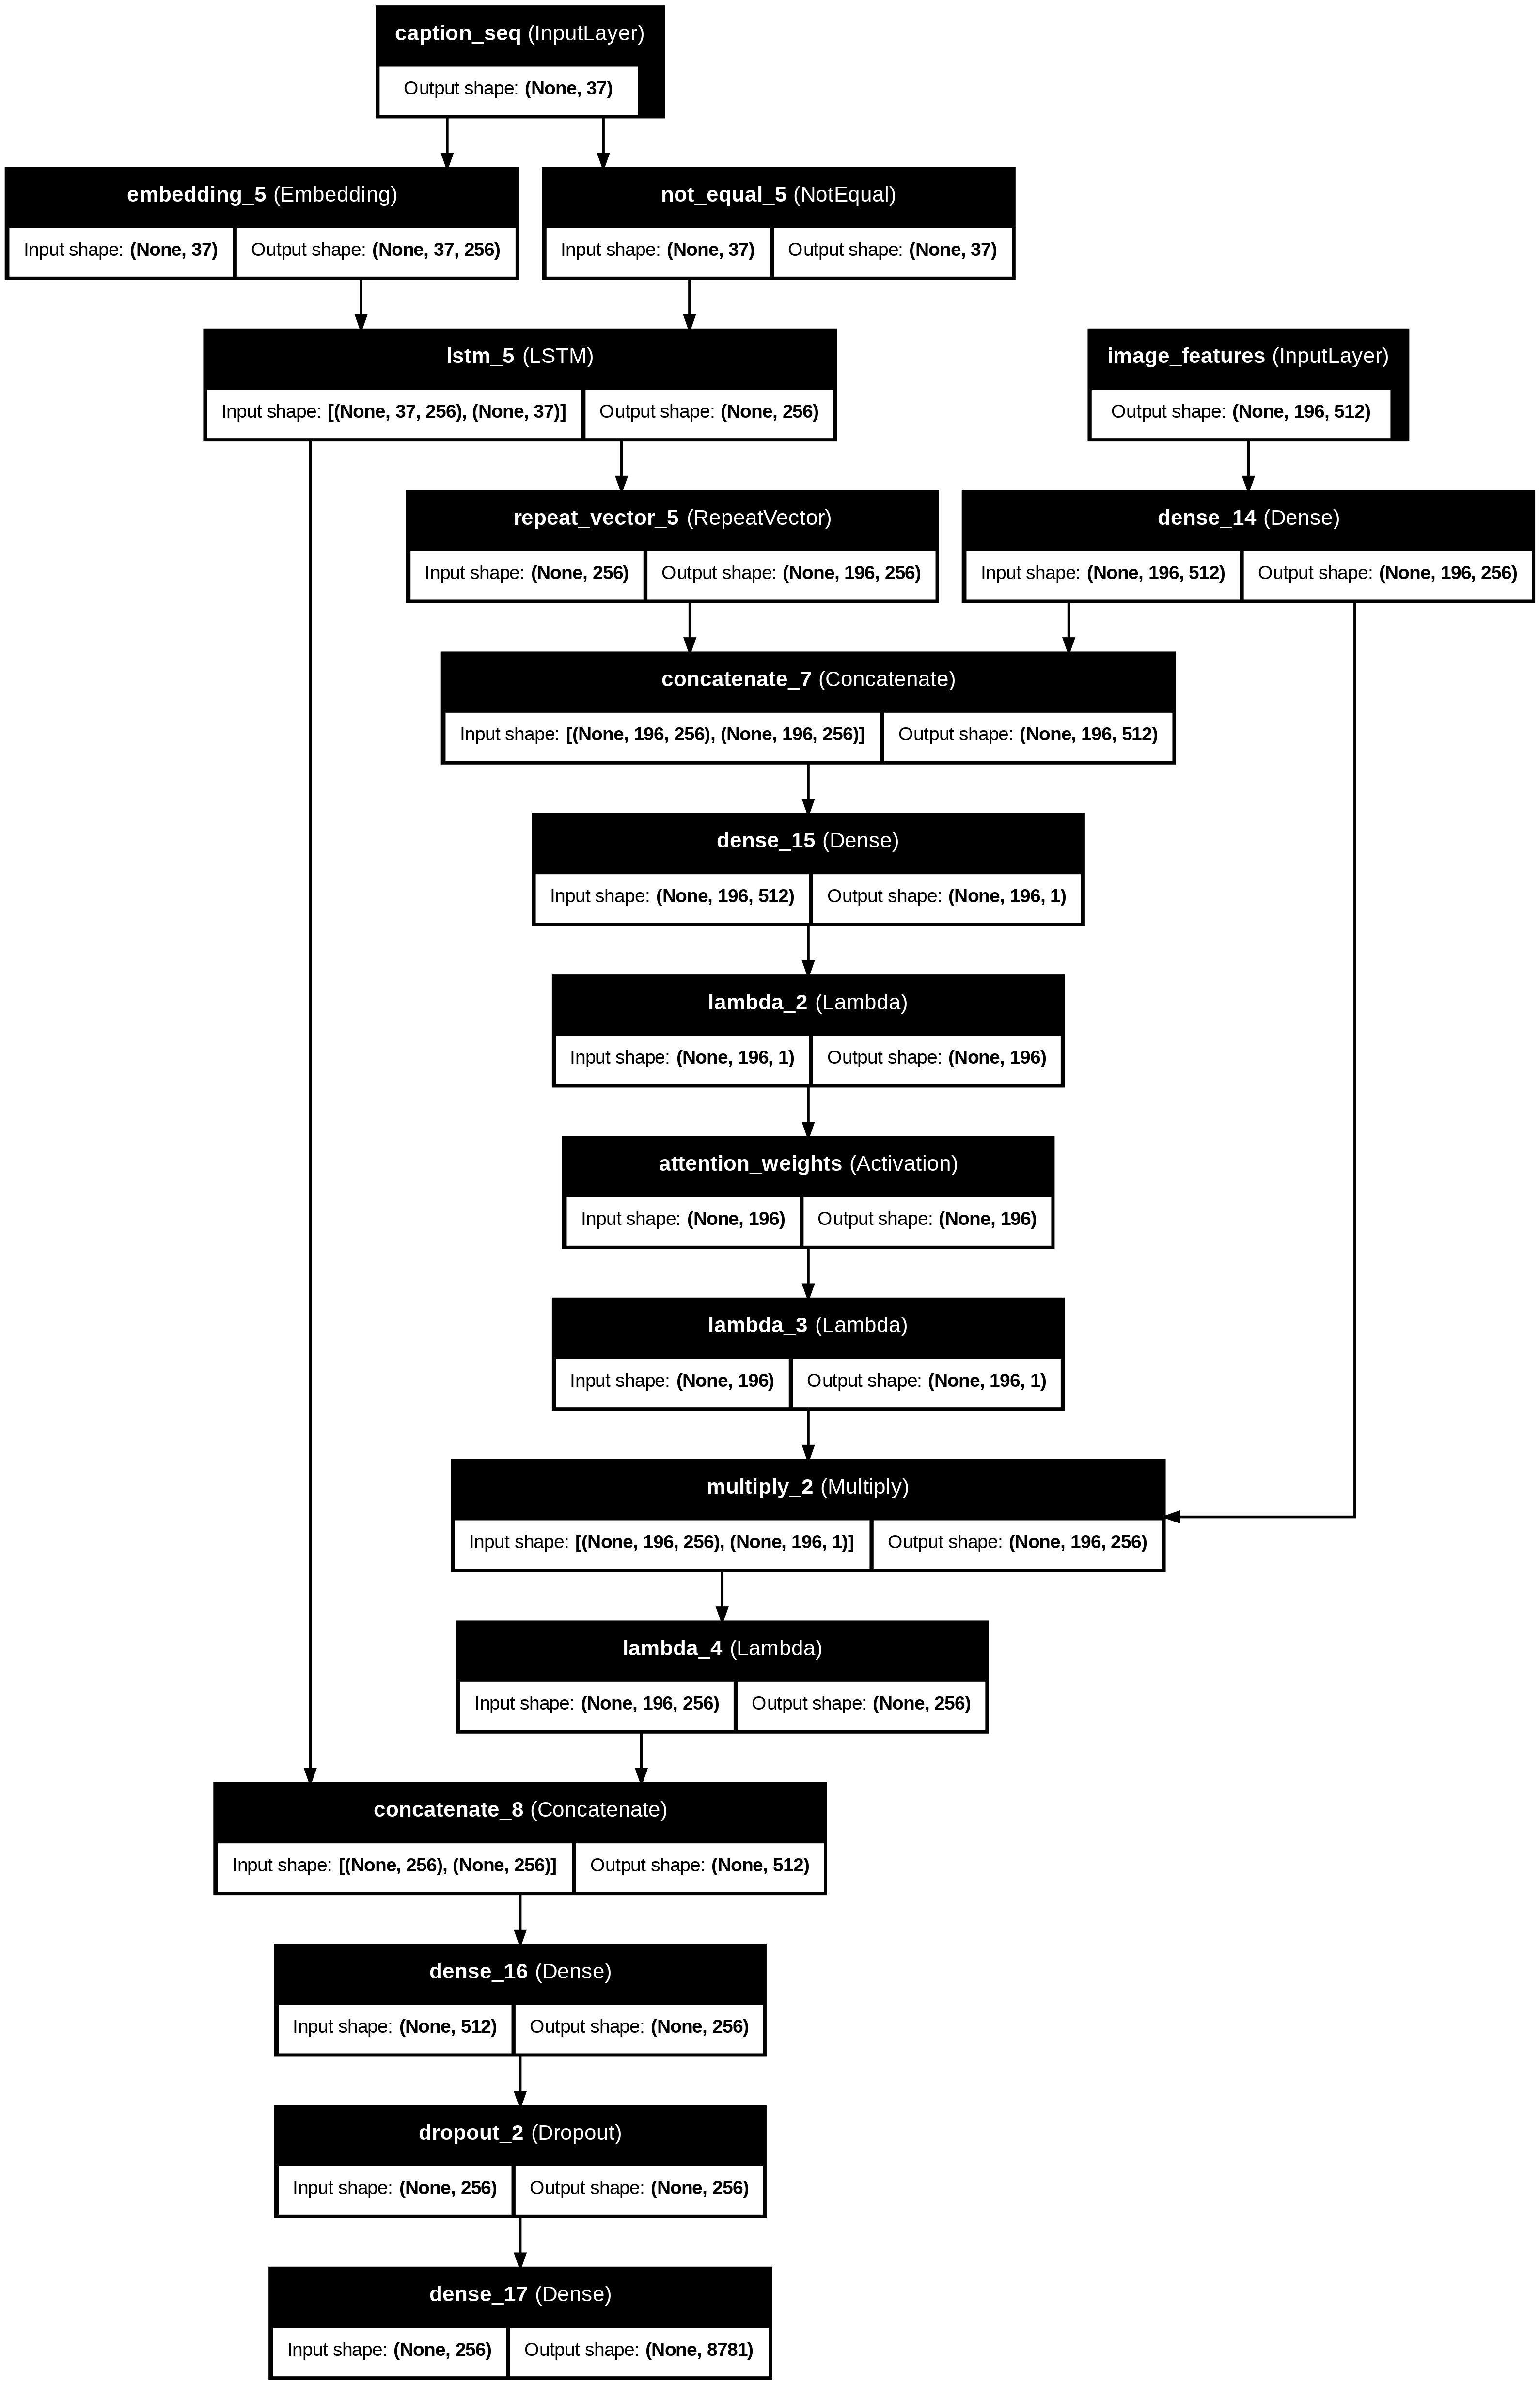

In [37]:
!pip install pydot
!apt-get install -y graphviz

tf.keras.utils.plot_model(model, to_file='/kaggle/working/model_architecture.png',
                            show_shapes=True, show_layer_names=True)

## Side-by-Side Caption Comparison 

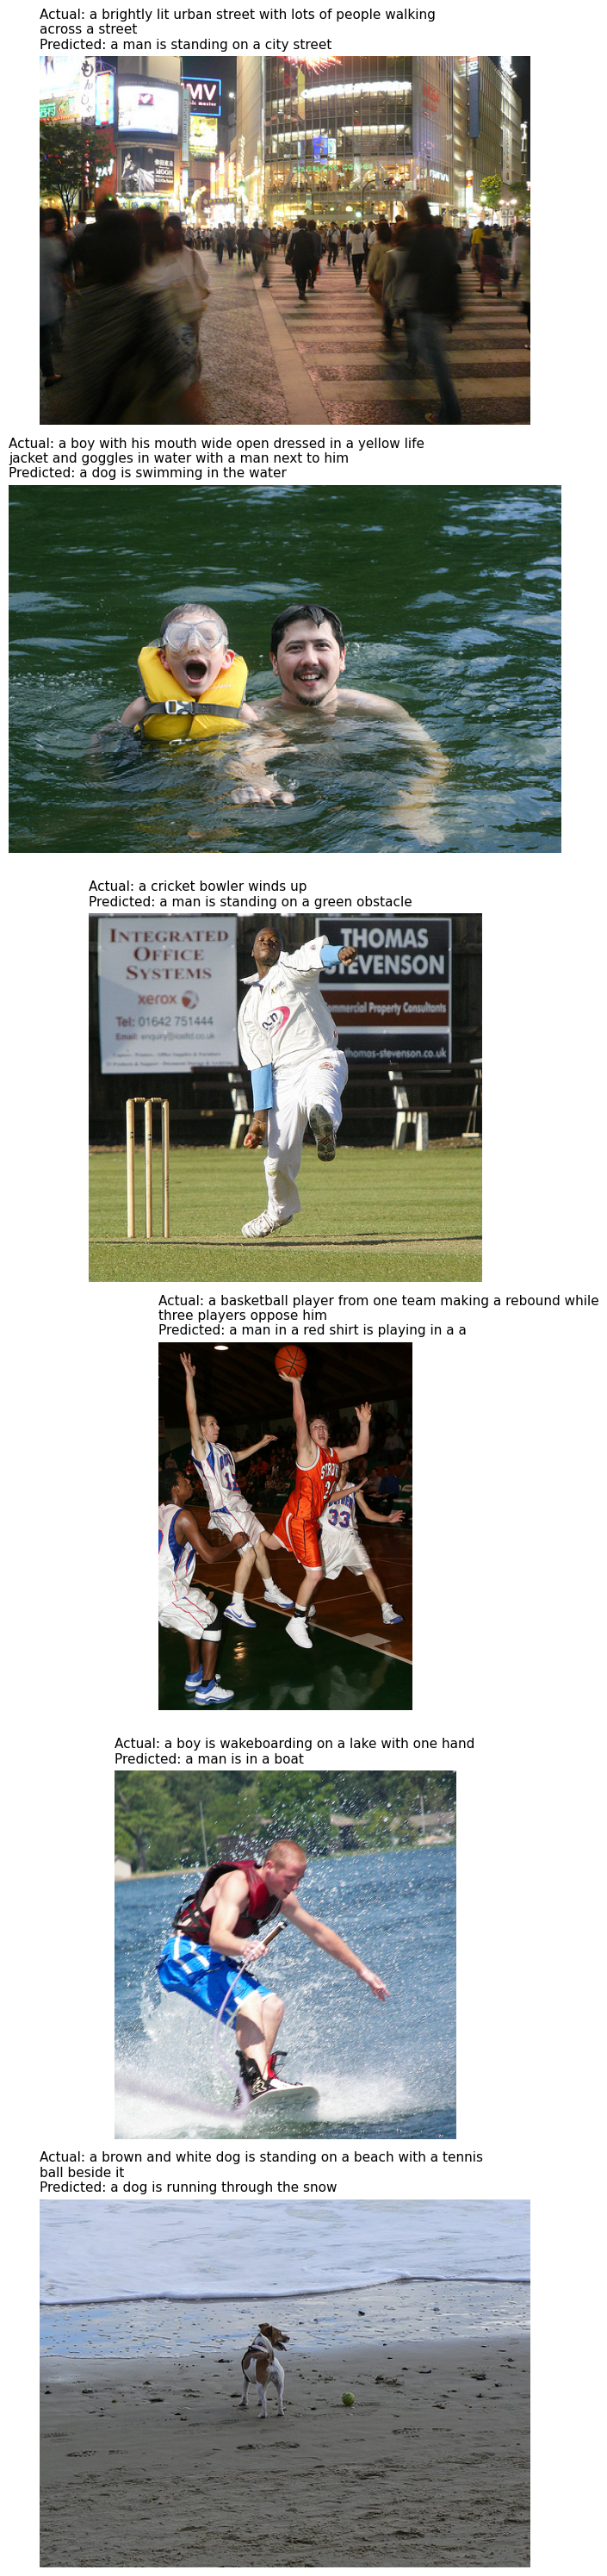

In [39]:
import matplotlib.pyplot as plt
from PIL import Image
import textwrap

def show_comparison(img_ids, n=6):
    fig, axes = plt.subplots(n, 1, figsize=(8, 5*n))
    if n == 1:
        axes = [axes]

    for i, img_id in enumerate(img_ids[:n]):
        feature = np.load(f'/kaggle/working/features_npy/{img_id}.npy')
        pred_caption = generate_caption(feature, model, tokenizer, max_length)

        # Ground truth (sirf pehla reference caption, clean)
        actual_caption = captions_dict[img_id][0].replace('startseq', '').replace('endseq', '').strip()

        img = Image.open(os.path.join(IMAGE_DIR, img_id))

        axes[i].imshow(img)
        axes[i].axis('off')

        title_text = (f"Actual: {textwrap.fill(actual_caption, 60)}\n"
                       f"Predicted: {textwrap.fill(pred_caption, 60)}")
        axes[i].set_title(title_text, fontsize=11, loc='left', color='black')

    plt.tight_layout()
    plt.savefig('/kaggle/working/final_comparison.png', dpi=150, bbox_inches='tight')
    plt.show()

# Test set se random 6 images lo comparison ke liye
import random
random.seed(42)
sample_ids = random.sample(test_ids, 6)
show_comparison(sample_ids, n=6)